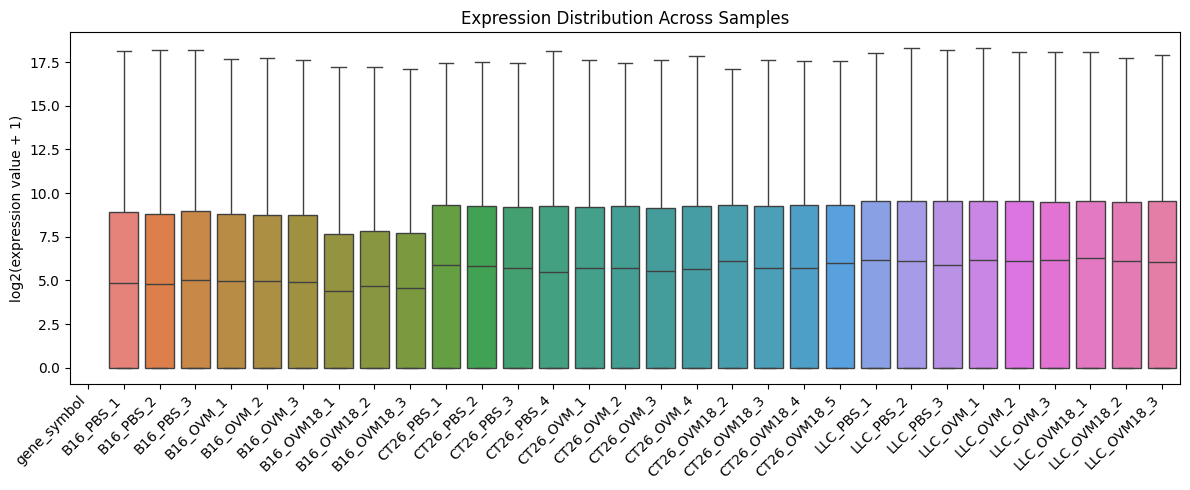

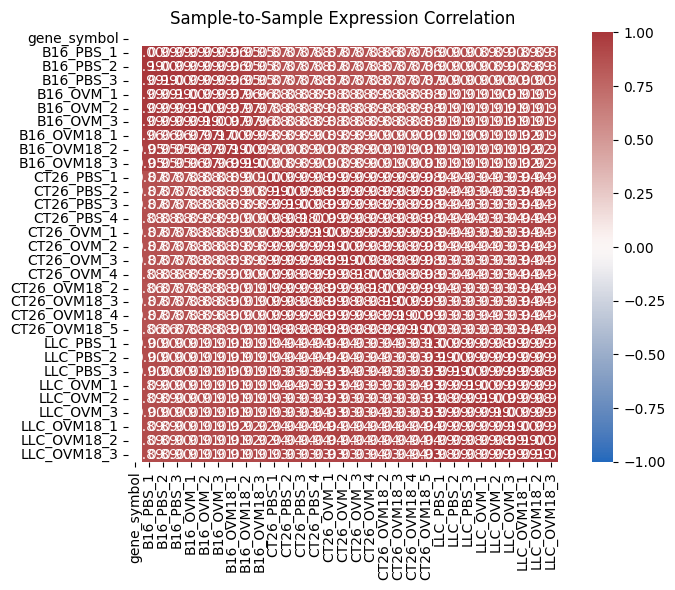

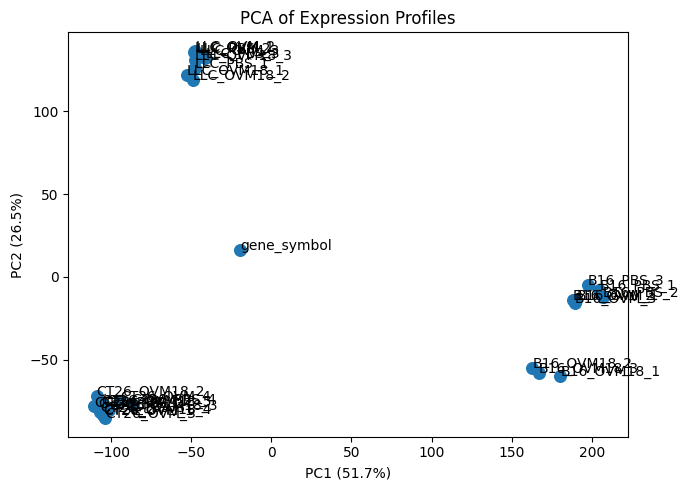

Charts saved successfully.


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the expression matrix:
# First column = gene IDs; remaining columns = samples
df = pd.read_csv("expression_matrix.tsv", sep="\t")

gene_ids = df.iloc[:, 0]
expr = df.iloc[:, 1:].apply(pd.to_numeric, errors="coerce")
expr.index = gene_ids

# Remove genes with no usable values
expr = expr.dropna(how="all")
expr = expr.loc[expr.notna().any(axis=1)]

# For plotting only: log-transform nonnegative expression values.

if (expr.fillna(0) < 0).any().any():
    raise ValueError("Check whether the expression matrix is suitable for log2(x+1).")

log_expr = np.log2(expr + 1)

# 1. Boxplot: expression distribution by sample
plt.figure(figsize=(12, 5))
sns.boxplot(data=log_expr, showfliers=False)
plt.xticks(rotation=45, ha="right")
plt.ylabel("log2(expression value + 1)")
plt.title("Expression Distribution Across Samples")
plt.tight_layout()
plt.savefig("01_expression_boxplot.png", dpi=300)
plt.show()

# 2. Correlation heatmap: sample-level similarity
corr = log_expr.corr(method="pearson", min_periods=2)

plt.figure(figsize=(8, 6))
sns.heatmap(corr, vmin=-1, vmax=1, cmap="vlag",
            annot=True, fmt=".2f", square=True)
plt.title("Sample-to-Sample Expression Correlation")
plt.tight_layout()
plt.savefig("02_sample_correlation.png", dpi=300)
plt.show()

# 3. PCA: broad patterns of sample variation
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Keep genes with at least one non-missing value;
# impute remaining missing values with each gene's median.
pca_input = log_expr.T.copy()
pca_input = pca_input.fillna(pca_input.median(axis=0))
pca_input = pca_input.loc[:, pca_input.nunique() > 1]

if pca_input.shape[0] >= 3 and pca_input.shape[1] >= 2:
    # Center genes but do not scale each gene to unit variance.
    X = pca_input.to_numpy()
    X = X - X.mean(axis=0, keepdims=True)

    pca = PCA(n_components=2)
    pcs = pca.fit_transform(X)

    plt.figure(figsize=(7, 5))
    plt.scatter(pcs[:, 0], pcs[:, 1], s=70)
    for i, sample in enumerate(pca_input.index):
        plt.annotate(str(sample), (pcs[i, 0], pcs[i, 1]))
    plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
    plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
    plt.title("PCA of Expression Profiles")
    plt.tight_layout()
    plt.savefig("03_expression_pca.png", dpi=300)
    plt.show()
else:
    print("Not enough variable genes or samples for PCA.")

print("Charts saved successfully.")
